In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from solve_dae.integrate import solve_dae
import numpy as np
from rfbmodel1D.parameters.params import SimulationParams, Vars
from rfbmodel1D.cells.cell import Cell
import matplotlib.pyplot as plt
import rfbmodel1D
import pandas as pd

In [2]:
# ---------------------------------------------------------------------
# Setup: Create cell and initialize parameters
# ---------------------------------------------------------------------
sim_params = SimulationParams
cell = Cell(params=sim_params)
#cell.modify_BC(Vars.phi_el, "cathode", "left", "dirichlet", 1.1)
cell.bc_mode = "galvanostatic" # Set BC mode to galvanostatic
cell.modify_BC(Vars.phi_el, "cathode", "left", "galvanostatic", 1000)

In [3]:
# ==============================================================================
# SIMULATION PARAMETERS 
# ==============================================================================
SOC = 0.2                  # [0-1] State of charge
V_tank = 0.005                 # [m³] Tank volume

# Derived tank concentrations from SOC
c_T_V4   = (1 - SOC) * 1000   # V(IV) concentration [mol/m³]
c_T_V5   = SOC * 1000         # V(V) concentration [mol/m³]
c_T_H    = 4963               # H+ concentration [mol/m³]
c_T_HSO4 = c_T_H * 3/5        # HSO4⁻ concentration [mol/m³]

# Tank state vector
c_0 = np.array([c_T_V4, c_T_V5, c_T_H, c_T_HSO4, V_tank])

# Initialize full DAE state from tank concentrations
# This will propagate the tank values through cathode, membrane, and anode
y0, yp0 = cell.initialize_dae_state(c_0, xtol=1e-6)

## Condición de borde en interfase cátodo/membrana

In [4]:
bc_h_ca_right = cell.bc[Vars.c_h]["cathode"]["right"]
print("type =", bc_h_ca_right.type)
print("Condición de borde en interfase catodo/membrana, lado catodo, de H+ es", bc_h_ca_right.value)


type = dirichlet
Condición de borde en interfase catodo/membrana, lado catodo, de H+ es 4961.401261180898


## Comportamiento de los potenciales

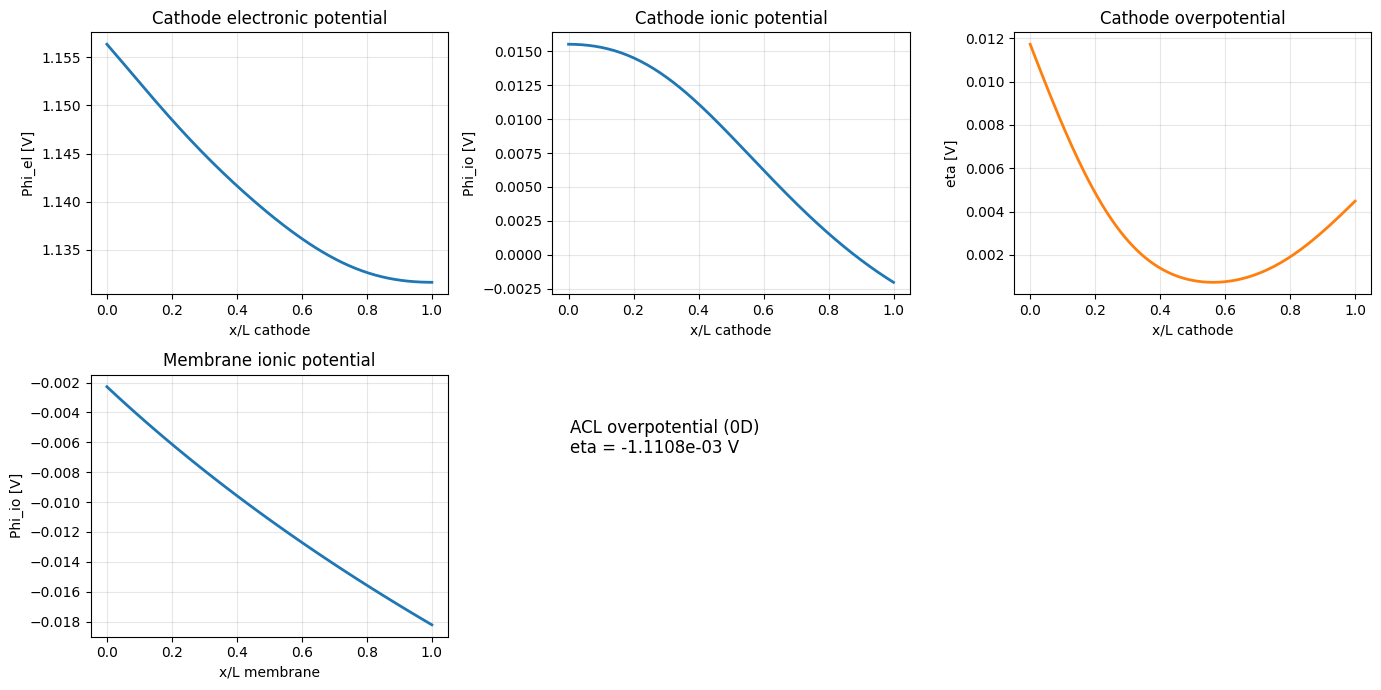

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Layout
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

n_tank = cell.layout.n_vars_tank
n_ca   = cell.layout.n_vars_cathode
n_mem  = cell.layout.n_vars_membrane
n_an   = cell.layout.n_vars_anode

off_tank = 0
off_ca   = off_tank + n_tank
off_mem  = off_ca + Nc * n_ca
off_an   = off_mem + Nm * n_mem

y_ca  = y0[off_ca:off_mem].reshape(Nc, n_ca)
y_mem = y0[off_mem:off_an].reshape(Nm, n_mem)
y_an  = y0[off_an:off_an + n_an]

phi_el_ca  = y_ca[:, 4]
phi_io_ca  = y_ca[:, 5]
phi_io_mem = y_mem[:, 1]
eta_acl    = y_an[3]
eta_ca     = cell.cathode.eta   # updated by last residual call inside initialize

x_ca  = np.linspace(0, 1, Nc)
x_mem = np.linspace(0, 1, Nm)

fig, ax = plt.subplots(2, 3, figsize=(14, 7))

ax[0, 0].plot(x_ca, phi_el_ca, lw=2)
ax[0, 0].set_title("Cathode electronic potential")
ax[0, 0].set_xlabel("x/L cathode")
ax[0, 0].set_ylabel("Phi_el [V]")
ax[0, 0].grid(True, alpha=0.3)

ax[0, 1].plot(x_ca, phi_io_ca, lw=2)
ax[0, 1].set_title("Cathode ionic potential")
ax[0, 1].set_xlabel("x/L cathode")
ax[0, 1].set_ylabel("Phi_io [V]")
ax[0, 1].grid(True, alpha=0.3)

ax[0, 2].plot(x_ca, eta_ca, lw=2, color="tab:orange")
ax[0, 2].set_title("Cathode overpotential")
ax[0, 2].set_xlabel("x/L cathode")
ax[0, 2].set_ylabel("eta [V]")
ax[0, 2].grid(True, alpha=0.3)

ax[1, 0].plot(x_mem, phi_io_mem, lw=2)
ax[1, 0].set_title("Membrane ionic potential")
ax[1, 0].set_xlabel("x/L membrane")
ax[1, 0].set_ylabel("Phi_io [V]")
ax[1, 0].grid(True, alpha=0.3)

ax[1, 1].axis("off")
ax[1, 1].text(0.05, 0.7, f"ACL overpotential (0D)\neta = {eta_acl:.4e} V", fontsize=12)

ax[1, 2].axis("off")

plt.tight_layout()
plt.show()

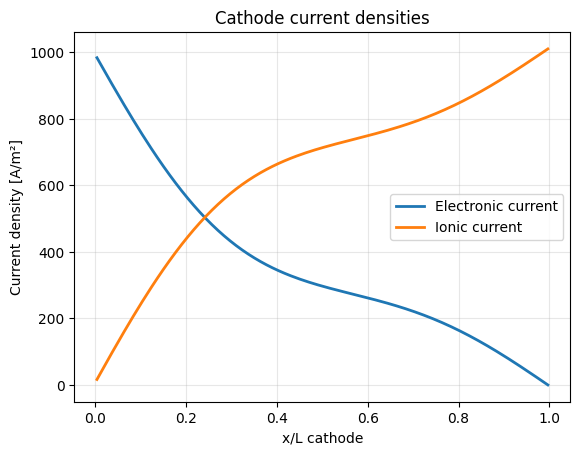

In [6]:
# After y_ca is available (same cell or new cell)
i_el_ca, i_io_ca = cell.compute_currents_from_potential(phi_el_ca, phi_io_ca, "cathode")
# East-face positions (normalized)
x_faces = np.linspace(0.5 / Nc, 1 - 0.5 / Nc, Nc)
plt.plot(x_faces, i_el_ca, lw=2, label="Electronic current")
plt.plot(x_faces, i_io_ca, lw=2, color="tab:orange", label="Ionic current")
plt.title("Cathode current densities")
plt.xlabel("x/L cathode")
plt.ylabel("Current density [A/m²]")
plt.grid(True, alpha=0.3)
plt.legend()

In [7]:

phi_io_ca_right_bc = cell.bc[Vars.phi_io]["cathode"]["right"]
phi_io_mem_left_bc = cell.bc[Vars.phi_io]["membrane"]["left"]

print("cathode right:", phi_io_ca_right_bc.type, phi_io_ca_right_bc.value)
print("membrane left:", phi_io_mem_left_bc.type, phi_io_mem_left_bc.value)

cathode right: neumann -5.85978251864293
membrane left: neumann -163.6737566360361


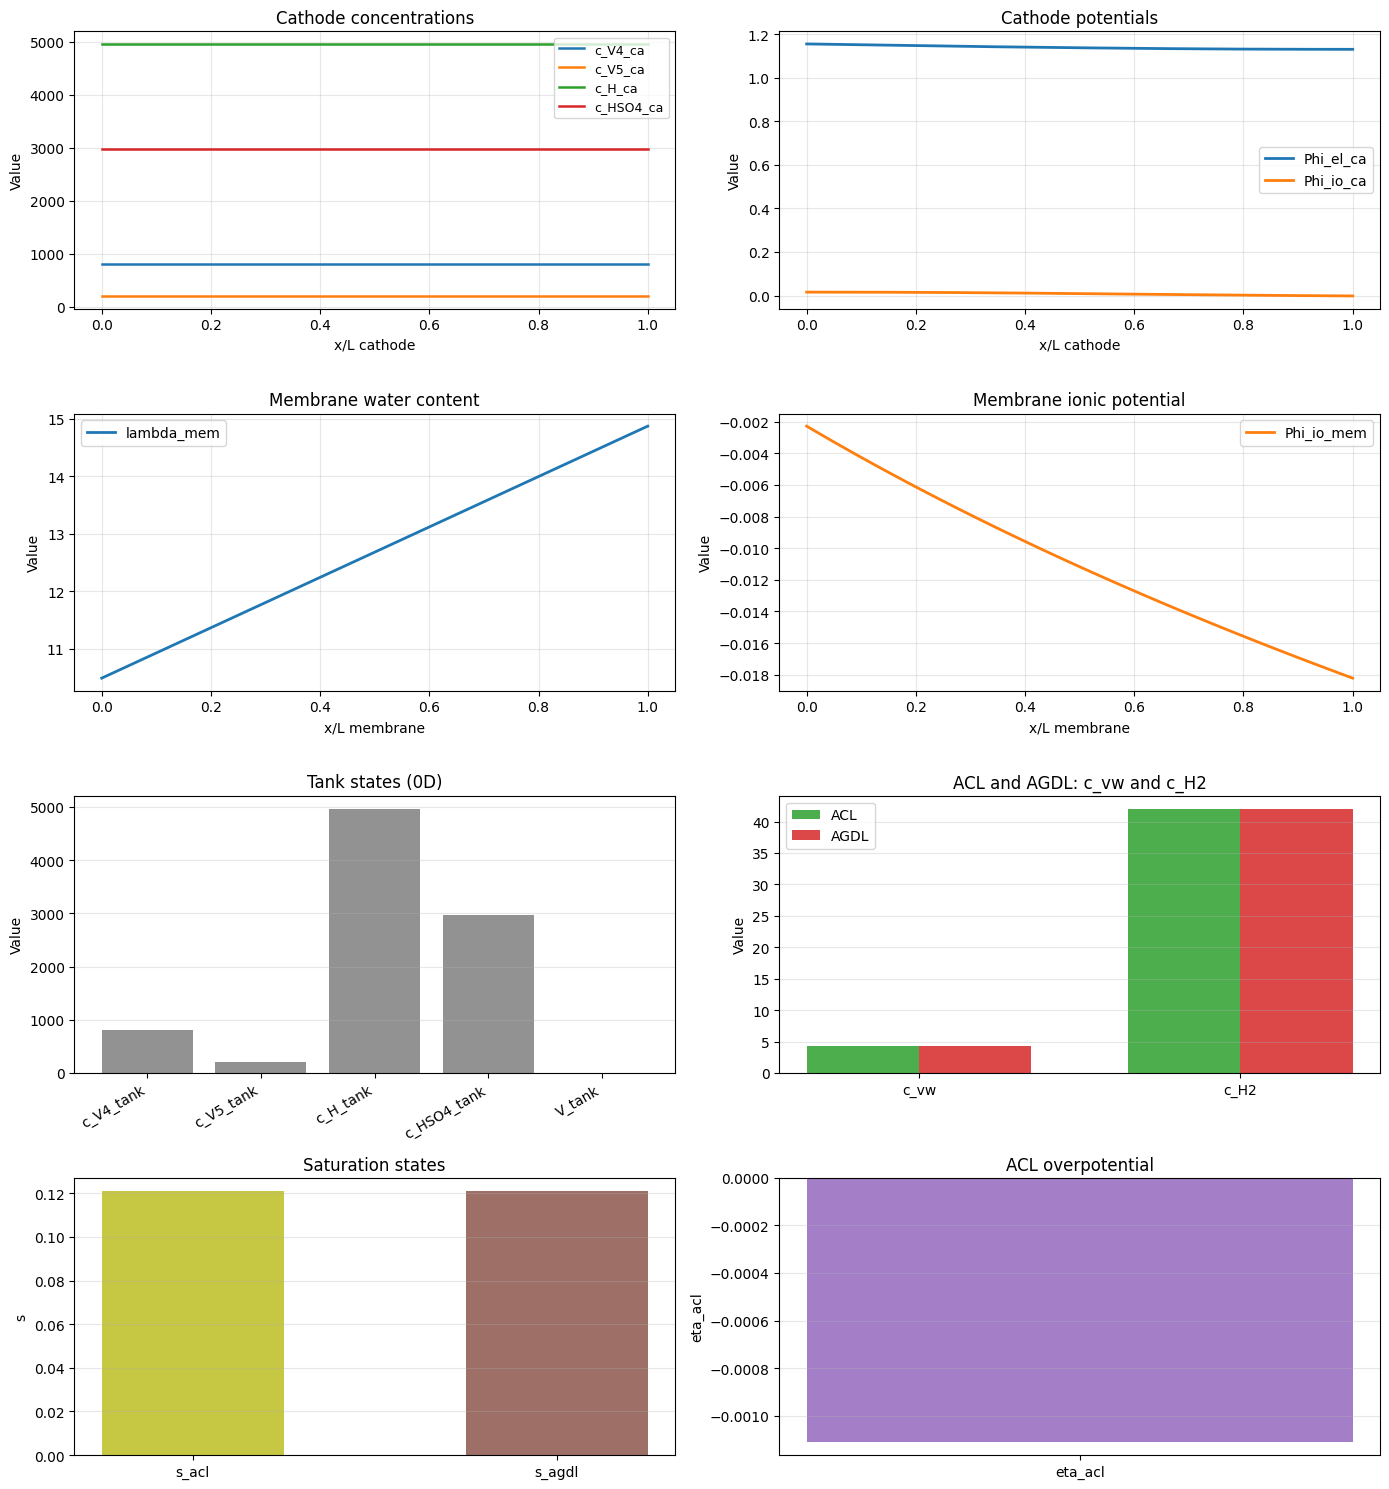

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

# ---------- pick state ----------
y_plot = y0

# ---------- layout ----------
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

n_tank = cell.layout.n_vars_tank
n_ca   = cell.layout.n_vars_cathode
n_mem  = cell.layout.n_vars_membrane
n_an   = cell.layout.n_vars_anode

off_tank = 0
off_ca   = off_tank + n_tank
off_mem  = off_ca + Nc * n_ca
off_an   = off_mem + Nm * n_mem

# ---------- unpack ----------
y_tank = y_plot[off_tank:off_ca]
y_ca   = y_plot[off_ca:off_mem].reshape(Nc, n_ca)
y_mem  = y_plot[off_mem:off_an].reshape(Nm, n_mem)
y_an   = y_plot[off_an:off_an + n_an]

# Cathode split
c_ca      = y_ca[:, :4]
phi_el_ca = y_ca[:, 4]
phi_io_ca = y_ca[:, 5]

# Membrane split
lam_mem    = y_mem[:, 0]
phi_io_mem = y_mem[:, 1]

# Anode split (0D)
y_acl  = y_an[:4]   # c_vw_acl, c_H2_acl, s_acl, eta_acl
y_agdl = y_an[4:]   # c_vw_agdl, c_H2_agdl, s_agdl

# Names
ca_c_names = ["c_V4_ca", "c_V5_ca", "c_H_ca", "c_HSO4_ca"]
tank_names = ["c_V4_tank", "c_V5_tank", "c_H_tank", "c_HSO4_tank", "V_tank"]

x_ca  = np.linspace(0, 1, Nc)
x_mem = np.linspace(0, 1, Nm)

# ---------- figure ----------
fig, ax = plt.subplots(4, 2, figsize=(14, 15))

# (1,1) Cathode concentrations
for i in range(4):
    ax[0, 0].plot(x_ca, c_ca[:, i], lw=1.8, label=ca_c_names[i])
ax[0, 0].set_title("Cathode concentrations")
ax[0, 0].set_xlabel("x/L cathode")
ax[0, 0].set_ylabel("Value")
ax[0, 0].grid(True, alpha=0.3)
ax[0, 0].legend(fontsize=9)

# (1,2) Cathode potentials
ax[0, 1].plot(x_ca, phi_el_ca, lw=2, label="Phi_el_ca")
ax[0, 1].plot(x_ca, phi_io_ca, lw=2, label="Phi_io_ca")
ax[0, 1].set_title("Cathode potentials")
ax[0, 1].set_xlabel("x/L cathode")
ax[0, 1].set_ylabel("Value")
ax[0, 1].grid(True, alpha=0.3)
ax[0, 1].legend()

# (2,1) Membrane lambda
ax[1, 0].plot(x_mem, lam_mem, lw=2, color="tab:blue", label="lambda_mem")
ax[1, 0].set_title("Membrane water content")
ax[1, 0].set_xlabel("x/L membrane")
ax[1, 0].set_ylabel("Value")
ax[1, 0].grid(True, alpha=0.3)
ax[1, 0].legend()

# (2,2) Membrane ionic potential
ax[1, 1].plot(x_mem, phi_io_mem, lw=2, color="tab:orange", label="Phi_io_mem")
ax[1, 1].set_title("Membrane ionic potential")
ax[1, 1].set_xlabel("x/L membrane")
ax[1, 1].set_ylabel("Value")
ax[1, 1].grid(True, alpha=0.3)
ax[1, 1].legend()

# (3,1) Tank 0D
x_tank = np.arange(len(tank_names))
ax[2, 0].bar(x_tank, y_tank, color="tab:gray", alpha=0.85)
ax[2, 0].set_title("Tank states (0D)")
ax[2, 0].set_ylabel("Value")
ax[2, 0].set_xticks(x_tank)
ax[2, 0].set_xticklabels(tank_names, rotation=30, ha="right")
ax[2, 0].grid(True, axis="y", alpha=0.3)

# (3,2) ACL + AGDL c_vw and c_H2 together
x_pair = np.array([0, 1])
w = 0.35
acl_pair  = np.array([y_acl[0], y_acl[1]])   # c_vw_acl, c_H2_acl
agdl_pair = np.array([y_agdl[0], y_agdl[1]]) # c_vw_agdl, c_H2_agdl

ax[2, 1].bar(x_pair - w/2, acl_pair,  width=w, color="tab:green", alpha=0.85, label="ACL")
ax[2, 1].bar(x_pair + w/2, agdl_pair, width=w, color="tab:red",   alpha=0.85, label="AGDL")
ax[2, 1].set_title("ACL and AGDL: c_vw and c_H2")
ax[2, 1].set_ylabel("Value")
ax[2, 1].set_xticks([0, 1])
ax[2, 1].set_xticklabels(["c_vw", "c_H2"])
ax[2, 1].grid(True, axis="y", alpha=0.3)
ax[2, 1].legend()

# (4,1) Saturation separate
x_sat = np.array([0, 1])
sat_vals = np.array([y_acl[2], y_agdl[2]])  # s_acl, s_agdl
ax[3, 0].bar(x_sat, sat_vals, width=0.5, color=["tab:olive", "tab:brown"], alpha=0.85)
ax[3, 0].set_title("Saturation states")
ax[3, 0].set_ylabel("s")
ax[3, 0].set_xticks([0, 1])
ax[3, 0].set_xticklabels(["s_acl", "s_agdl"])
ax[3, 0].grid(True, axis="y", alpha=0.3)

# (4,2) Eta separate
ax[3, 1].bar([0], [y_acl[3]], width=0.5, color="tab:purple", alpha=0.85)
ax[3, 1].set_title("ACL overpotential")
ax[3, 1].set_ylabel("eta_acl")
ax[3, 1].set_xticks([0])
ax[3, 1].set_xticklabels(["eta_acl"])
ax[3, 1].grid(True, axis="y", alpha=0.3)

# plain number ticks
for a in ax.flatten():
    fmt = ScalarFormatter(useMathText=False)
    fmt.set_scientific(False)
    fmt.set_useOffset(False)
    a.yaxis.set_major_formatter(fmt)

plt.tight_layout()
plt.show()

In [9]:
# Membrane current density from solved phi_io profile (non-uniform dx_m supported, CORRECTED)
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x
n_tank = cell.layout.n_vars_tank
n_ca   = cell.layout.n_vars_cathode
n_mem  = cell.layout.n_vars_membrane

off_ca  = n_tank
off_mem = off_ca + Nc * n_ca
off_an  = off_mem + Nm * n_mem

y_mem = y0[off_mem:off_an].reshape(Nm, n_mem)
phi_io_mem = y_mem[:, 1]

dx_m = np.asarray(cell.mesh.membrane_mesh.dx) * cell.membrane.thickness  # ensure array
kappa_m = np.asarray(cell.membrane.kappa_io)  # length Nm

# Compute cell center positions
edges_m = np.concatenate([[0.0], np.cumsum(dx_m)])
x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])
# Face positions and widths
# For N nodes, there are N-1 faces between them
# dx_face_m = x_center_m[1:] - x_center_m[:-1]
dx_face_m = x_center_m[1:] - x_center_m[:-1]
# Harmonic mean for kappa at faces
kappa_face = 2 * kappa_m[:-1] * kappa_m[1:] / (kappa_m[:-1] + kappa_m[1:] + 1e-30)
dphi_dx = (phi_io_mem[1:] - phi_io_mem[:-1]) / dx_face_m

i_mem_faces = -kappa_face * dphi_dx

# Optional: left and right boundary current from BCs
bc_left  = cell.bc[Vars.phi_io]["membrane"]["left"]
bc_right = cell.bc[Vars.phi_io]["membrane"]["right"]

# LEFT BOUNDARY. CATHODE - MEMBRANE INTERFACE
if bc_left.type == "dirichlet":
    i_left = -kappa_m[0] * (phi_io_mem[0] - bc_left.value) / (dx_m[0] / 2)
elif bc_left.type == "neumann":
    # bc.value = dPhi/dx
    i_left = -kappa_m[0] * bc_left.value
else:
    raise ValueError(f"Unsupported left BC type: {bc_left.type}")
# RIGHT BOUNDARY. MEMBRANE ANODE INTERFACE
if bc_right.type == "dirichlet":
    i_right = -kappa_m[-1] * (bc_right.value - phi_io_mem[-1]) / (dx_m[-1] / 2)
elif bc_right.type == "neumann":
    # bc.value = dPhi/dx
    i_right = -kappa_m[-1] * bc_right.value
else:
    raise ValueError(f"Unsupported right BC type: {bc_right.type}")

print("left BC :", bc_left.type, bc_left.value)
print("right BC:", bc_right.type, bc_right.value)
print("i_left_BC  [A/m2] =", i_left)
print("i_right_BC [A/m2] =", i_right)
print("phi_io_mem[0], left BC value =", phi_io_mem[0], bc_left.value)
print("phi_io_mem[-1], right BC value =", phi_io_mem[-1], bc_right.value)


left BC : neumann -163.6737566360361
right BC: dirichlet -0.01834862982415984
i_left_BC  [A/m2] = 1010.0760331426147
i_right_BC [A/m2] = 1010.0760331426167
phi_io_mem[0], left BC value = -0.002277148216864119 -163.6737566360361
phi_io_mem[-1], right BC value = -0.018218512522118206 -0.01834862982415984


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ============= EXTRACT ALL DATA =============
# Layout
Nc = cell.mesh.cathode_mesh.n_x
Nm = cell.mesh.membrane_mesh.n_x

n_tank = cell.layout.n_vars_tank
n_ca   = cell.layout.n_vars_cathode
n_mem  = cell.layout.n_vars_membrane
n_an   = cell.layout.n_vars_anode

off_tank = 0
off_ca   = off_tank + n_tank
off_mem  = off_ca + Nc * n_ca
off_an   = off_mem + Nm * n_mem

# Extract states
y_ca  = y0[off_ca:off_mem].reshape(Nc, n_ca)
y_mem = y0[off_mem:off_an].reshape(Nm, n_mem)
y_an  = y0[off_an:off_an + n_an]

# Cathode potentials (distributed)
phi_el_ca = y_ca[:, 4]
phi_io_ca = y_ca[:, 5]

# Membrane potentials (distributed)
phi_io_mem = y_mem[:, 1]

# Anode potentials (0D - scalars)
# The anode is 0D, so we extract scalar values
n_acl = 4
n_agdl = 3
# Try to get potentials - if layout changes this may need update
if len(y_an) > n_acl + n_agdl:
    phi_el_an = y_an[n_acl + n_agdl]
    phi_io_an = y_an[n_acl + n_agdl + 1]
else:
    # Use boundary condition value for anode
    phi_el_an = 0.0
    phi_io_an = cell.bc[Vars.phi_io]["anode"]["left"].value

print(f"Cathode nodes: {Nc}")
print(f"Membrane nodes: {Nm}")
print(f"Anode: 0D (scalar)")
print(f"Anode phi_el={phi_el_an:.6f}, phi_io={phi_io_an:.6f}")

# ============= CREATE COMBINED COORDINATE SYSTEM =============
# Normalized positions in each domain
x_ca_norm = np.linspace(0, 1, Nc)  # [0, 1]
x_mem_norm = np.linspace(0, 1, Nm)  # [0, 1]

# Combined axis: Cathode [0,1] -> Membrane [1,2] -> Anode [2,2.1]
L_ca = 1.0
L_mem = 1.0
L_an = 0.1  # Small segment for anode (0D)

x_combined_ca = x_ca_norm * L_ca
x_combined_mem = L_ca + x_mem_norm * L_mem
x_combined_an = L_ca + L_mem + L_an / 2

print(f"Cathode x range: [{x_combined_ca[0]:.2f}, {x_combined_ca[-1]:.2f}]")
print(f"Membrane x range: [{x_combined_mem[0]:.2f}, {x_combined_mem[-1]:.2f}]")
print(f"Anode x position: {x_combined_an:.2f}")

# ============= COMPUTE CURRENTS =============
# Cathode currents from potentials (computed at faces for non-uniform dx)
dx_ca = np.asarray(cell.mesh.cathode_mesh.dx) * cell.cathode.thickness
edges_ca = np.concatenate([[0.0], np.cumsum(dx_ca)])
x_center_ca = 0.5 * (edges_ca[:-1] + edges_ca[1:])
dx_face_ca = x_center_ca[1:] - x_center_ca[:-1]
x_faces_ca    = 0.5 * (x_combined_ca[:-1] + x_combined_ca[1:])
i_el_ca       = -cell.cathode.eff_conductivity * (phi_el_ca[1:] - phi_el_ca[:-1]) / dx_face_ca
kappa_ca      = cell.cathode.kappa_io
dx_ca_right = dx_ca[1:] 
dx_ca_left  = dx_ca[:-1]
kappa_ca_face = (dx_ca_right * kappa_ca[:-1] + dx_ca_left * kappa_ca[1:]) / (dx_ca_right + dx_ca_left + 1e-30)  # weighted average for non-uniform grid
# For ionic current, use same dx_face_ca
i_io_ca = -kappa_ca_face * (phi_io_ca[1:] - phi_io_ca[:-1]) / dx_face_ca
# Membrane ionic current (computed at faces for non-uniform dx)
dx_m = np.asarray(cell.mesh.membrane_mesh.dx) * cell.membrane.thickness
edges_m = np.concatenate([[0.0], np.cumsum(dx_m)])
x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])
dx_face_m = x_center_m[1:] - x_center_m[:-1]
x_faces_mem = 0.5 * (x_combined_mem[:-1] + x_combined_mem[1:])
kappa_m = np.asarray(cell.membrane.kappa_io)
kappa_e_mem = 0.5 * (kappa_m[:-1] + kappa_m[1:])
dphi_e_mem = (phi_io_mem[1:] - phi_io_mem[:-1]) / dx_face_m
i_io_mem = -kappa_e_mem * dphi_e_mem
# --- Consistency check at interface ---
print(f"Cathode ionic current at last face: {i_io_ca[-1]:.6e} A/m2")
print(f"Membrane ionic current at first face: {i_io_mem[0]:.6e} A/m2")
if not np.isclose(i_io_ca[-1], i_io_mem[0], rtol=1e-3, atol=1e-6):
    print("WARNING: Discontinuity in ionic current at cathode/membrane interface!")
    print(f"  i_io_ca[-1] = {i_io_ca[-1]:.6e}, i_io_mem[0] = {i_io_mem[0]:.6e}")
    print(f"  Discontinuity location: x = {x_faces_ca[-1]:.4f} (cathode/membrane interface)")
else:
    print("Ionic current is continuous at interface.")

# Anode current (from last cell computation self.i)
i_an = cell.i  # Total current from the anode
print(f"Anode total current: {i_an:.6e} A")


Cathode nodes: 150
Membrane nodes: 50
Anode: 0D (scalar)
Anode phi_el=0.000000, phi_io=0.000000
Cathode x range: [0.00, 1.00]
Membrane x range: [1.00, 2.00]
Anode x position: 2.05
Cathode ionic current at last face: 1.003906e+03 A/m2
Membrane ionic current at first face: 1.010115e+03 A/m2
  i_io_ca[-1] = 1.003906e+03, i_io_mem[0] = 1.010115e+03
  Discontinuity location: x = 0.9966 (cathode/membrane interface)
Anode total current: 0.000000e+00 A


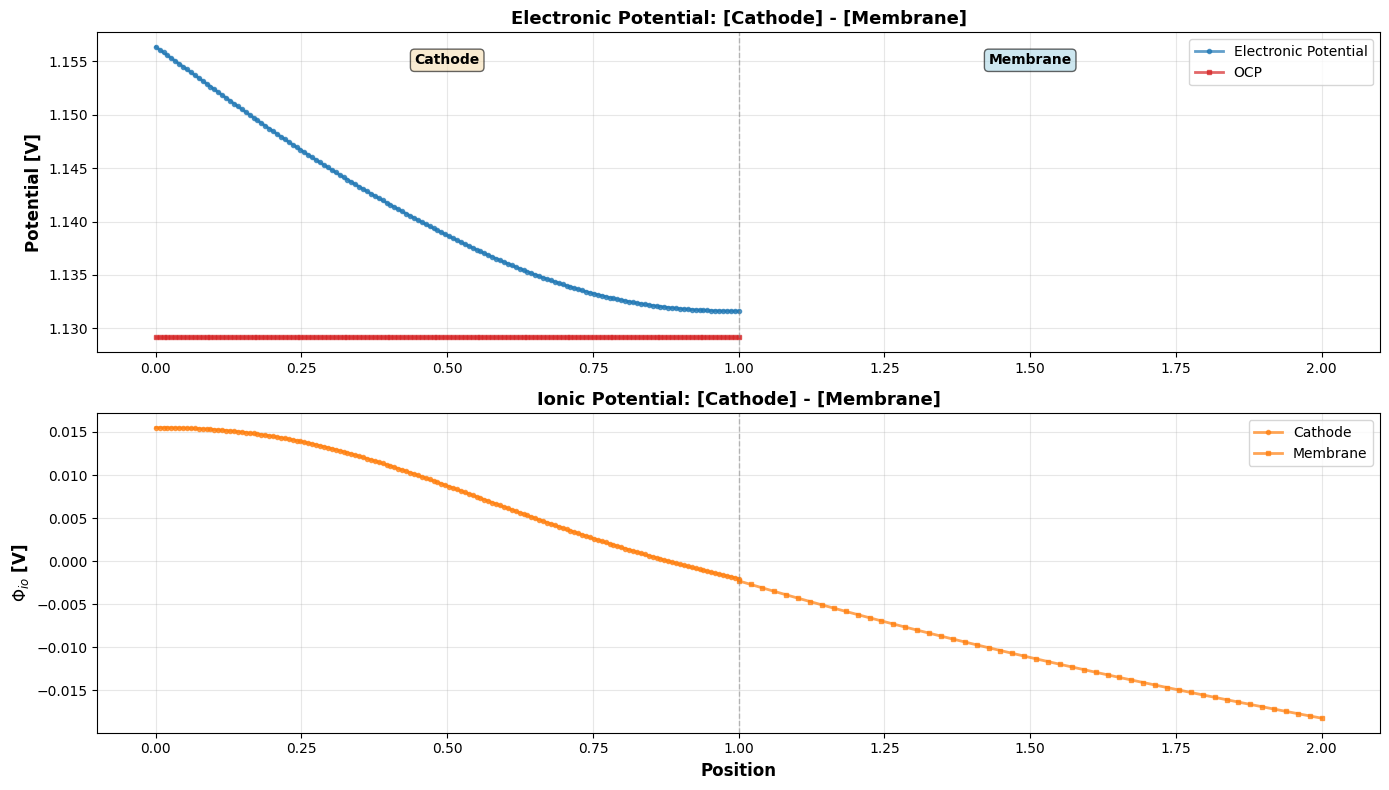

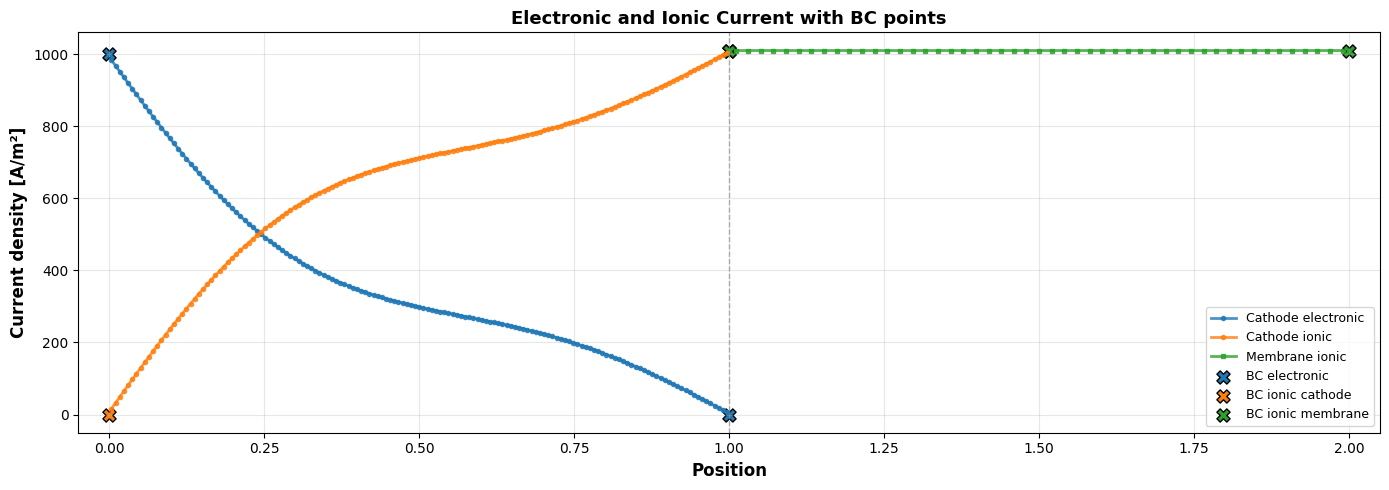

Electronic BC: galvanostatic neumann -> 1000.0 -0.0
Ionic cathode BC: neumann neumann -> -0.0 1010.0760331426145
Ionic membrane BC: neumann dirichlet -> 1010.0760331426147 1010.0760331426168


In [11]:
# ============= PLOT 1: POTENTIALS (phi_el, phi_io) - Only Cathode & Membrane =============
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

# Compute V_OCP for each cathode node
c_ca = y_ca[:, :4]  # Extract concentrations [c_V4, c_V5, c_H, c_HSO4]
V_OCP_ca = np.array([cell.compute_OCP(c_ca[i, :], "cathode") for i in range(Nc)])

# Plot phi_el (only cathode) - BLUE for _el
ax1.plot(x_combined_ca, phi_el_ca, 'o-', linewidth=2, markersize=3, label='Electronic Potential', color='tab:blue', alpha=0.7)
ax1.plot(x_combined_ca, V_OCP_ca, 's-', linewidth=2, markersize=3, label='OCP', color='tab:red', alpha=0.7)
ax1.axvline(x=L_ca, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax1.set_ylabel('Potential [V]', fontsize=12, fontweight='bold')
ax1.set_title('Electronic Potential: [Cathode] - [Membrane]', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10, loc='best')
ax1.set_xlim(-0.1, L_ca + L_mem + 0.1)

# Add domain labels
y_range = ax1.get_ylim()
y_pos = y_range[0] + (y_range[1] - y_range[0]) * 0.90
ax1.text(L_ca/2, y_pos, 'Cathode', ha='center', fontsize=10, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6))
ax1.text(L_ca + L_mem/2, y_pos, 'Membrane', ha='center', fontsize=10, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.6))

# Plot phi_io (cathode and membrane) - ORANGE for _io
ax2.plot(x_combined_ca, phi_io_ca, 'o-', linewidth=2, markersize=3, label='Cathode', color='tab:orange', alpha=0.7)
ax2.plot(x_combined_mem, phi_io_mem, 's-', linewidth=2, markersize=3, label='Membrane', color='tab:orange', alpha=0.7)
ax2.axvline(x=L_ca, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax2.set_xlabel('Position', fontsize=12, fontweight='bold')
ax2.set_ylabel('$\\Phi_{io}$ [V]', fontsize=12, fontweight='bold')
ax2.set_title('Ionic Potential: [Cathode] - [Membrane]', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=10, loc='best')
ax2.set_xlim(-0.1, L_ca + L_mem + 0.1)

plt.tight_layout()
plt.show()

# ============= PLOT: Ionic + Electronic Current + BC points =============
def bc_to_current(phi, bc, coeff, dx, side):
    """
    Convert potential BC to current density: i = -coeff * dPhi/dx
    bc.type can be 'dirichlet' or 'neumann'
    dx can be array or scalar (use first/last for left/right)
    """
    if bc.type == "neumann":
        dphi_dx = bc.value
    elif bc.type == "galvanostatic":
        dphi_dx = -bc.value / coeff  # bc.value is current density, so convert to dPhi/dx
    elif bc.type == "dirichlet":
        if side == "left":
            dphi_dx = (phi[0] - bc.value) / (dx[0] / 2 if hasattr(dx, '__len__') else dx / 2)
        elif side == "right":
            dphi_dx = (bc.value - phi[-1]) / (dx[-1] / 2 if hasattr(dx, '__len__') else dx / 2)
        else:
            raise ValueError("side must be 'left' or 'right'")
    else:
        return np.nan  # unsupported BC type
    return -coeff * dphi_dx

# Geometry and transport coefficients
dx_ca = np.asarray(cell.mesh.cathode_mesh.dx) * cell.cathode.thickness
dx_m  = np.asarray(cell.mesh.membrane_mesh.dx) * cell.membrane.thickness

sigma_ca = cell.cathode.eff_conductivity
kappa_ca = cell.cathode.kappa_io
kappa_m  = cell.membrane.kappa_io

# BC objects (potentials)
bc_phi_el_ca_L = cell.bc[Vars.phi_el]["cathode"]["left"]
bc_phi_el_ca_R = cell.bc[Vars.phi_el]["cathode"]["right"]

bc_phi_io_ca_L = cell.bc[Vars.phi_io]["cathode"]["left"]
bc_phi_io_ca_R = cell.bc[Vars.phi_io]["cathode"]["right"]

bc_phi_io_m_L = cell.bc[Vars.phi_io]["membrane"]["left"]
bc_phi_io_m_R = cell.bc[Vars.phi_io]["membrane"]["right"]

# Current from BCs
i_el_bc_L = bc_to_current(phi_el_ca, bc_phi_el_ca_L, sigma_ca, dx_ca, "left")
i_el_bc_R = bc_to_current(phi_el_ca, bc_phi_el_ca_R, sigma_ca, dx_ca, "right")

i_io_ca_bc_L = bc_to_current(phi_io_ca, bc_phi_io_ca_L, kappa_ca[0], dx_ca, "left")
i_io_ca_bc_R = bc_to_current(phi_io_ca, bc_phi_io_ca_R, kappa_ca[-1], dx_ca, "right")

i_io_m_bc_L = bc_to_current(phi_io_mem, bc_phi_io_m_L, kappa_m[0],  dx_m, "left")
i_io_m_bc_R = bc_to_current(phi_io_mem, bc_phi_io_m_R, kappa_m[-1], dx_m, "right")

# Plot main curves
fig, ax = plt.subplots(figsize=(14, 5))

# For cathode, plot at face positions (not node positions)
edges_ca = np.concatenate([[0.0], np.cumsum(dx_ca)])
x_center_ca = 0.5 * (edges_ca[:-1] + edges_ca[1:])
dx_face_ca = x_center_ca[1:] - x_center_ca[:-1]
x_faces_ca = 0.5 * (x_combined_ca[:-1] + x_combined_ca[1:])
ax.plot(x_faces_ca, i_el_ca, 'o-', linewidth=2, markersize=3,
        label='Cathode electronic', color='tab:blue', alpha=0.8)
ax.plot(x_faces_ca, i_io_ca, 'o-', linewidth=2, markersize=3,
        label='Cathode ionic', color='tab:orange', alpha=0.8)

# For membrane, plot at face positions
edges_m = np.concatenate([[0.0], np.cumsum(dx_m)])
x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])
dx_face_m = x_center_m[1:] - x_center_m[:-1]
x_faces_mem = 0.5 * (x_combined_mem[:-1] + x_combined_mem[1:])
ax.plot(x_faces_mem, i_io_mem, 's-', linewidth=2, markersize=3,
        label='Membrane ionic', color='tab:green', alpha=0.8)

# Interface line
ax.axvline(x=L_ca, color='gray', linestyle='--', alpha=0.6, linewidth=1)

# BC points (x positions in combined axis)
x_ca_L, x_ca_R = 0.0, L_ca
x_m_L,  x_m_R  = L_ca, L_ca + L_mem

# Electronic BC points
ax.scatter([x_ca_L, x_ca_R], [i_el_bc_L, i_el_bc_R],
           marker='X', s=90, color='tab:blue', edgecolor='k',
           label='BC electronic')

# Ionic BC points (cathode + membrane)
ax.scatter([x_ca_L, x_ca_R], [i_io_ca_bc_L, i_io_ca_bc_R],
           marker='X', s=90, color='tab:orange', edgecolor='k',
           label='BC ionic cathode')

ax.scatter([x_m_L, x_m_R], [i_io_m_bc_L, i_io_m_bc_R],
           marker='X', s=90, color='tab:green', edgecolor='k',
           label='BC ionic membrane')

# Labels/style
ax.set_xlabel('Position', fontsize=12, fontweight='bold')
ax.set_ylabel('Current density [A/m²]', fontsize=12, fontweight='bold')
ax.set_title('Electronic and Ionic Current with BC points', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc='best')
ax.set_xlim(-0.05, L_ca + L_mem + 0.05)

plt.tight_layout()
plt.show()

# Optional: print BC currents and BC types
print("Electronic BC:", bc_phi_el_ca_L.type, bc_phi_el_ca_R.type, "->", i_el_bc_L, i_el_bc_R)
print("Ionic cathode BC:", bc_phi_io_ca_L.type, bc_phi_io_ca_R.type, "->", i_io_ca_bc_L, i_io_ca_bc_R)
print("Ionic membrane BC:", bc_phi_io_m_L.type, bc_phi_io_m_R.type, "->", i_io_m_bc_L, i_io_m_bc_R)


In [12]:
labels = ["c_vw_acl", "c_H2_acl", "s_acl", "eta_acl", "c_vw_agdl", "c_H2_agdl", "s_agdl"]

start = len(y0) - 7
for k, (name, yv, ypv) in enumerate(zip(labels, y0[-7:], yp0[-7:])):
    i = start + k
    print(f"[{i:4d}] {name:10s}  y0 = {yv: .8e}   yp0 = {ypv: .8e}")

[1006] c_vw_acl    y0 =  4.20000000e+01   yp0 =  7.83538439e+02
[1007] c_H2_acl    y0 =  1.21000000e-01   yp0 = -7.97382275e-10
[1008] s_acl       y0 = -1.11081417e-03   yp0 =  0.00000000e+00
[1009] eta_acl     y0 =  4.35382736e+00   yp0 =  0.00000000e+00
[1010] c_vw_agdl   y0 =  4.20000000e+01   yp0 =  0.00000000e+00
[1011] c_H2_agdl   y0 =  1.21000000e-01   yp0 = -3.54696372e-06
[1012] s_agdl      y0 =  4.96140126e+03   yp0 =  0.00000000e+00
